# Ejercicio 9: Reconstrucción tomográfica con regularización cuadrática

En este ejercicio analizamos cómo cambian las reconstrucciones al modificar el nivel de ruido y la intensidad de la regularización. Para medir las diferencias entre píxeles vecinos, construimos la matriz $D$.

In [82]:
import numpy as np
import matplotlib.pyplot as plt

## Código reutilizado de ejercicios anteriores

In [83]:
# definimos el tamaño de la imagen
n = 8


# definimos el fantoma
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)


# vectorizamos el fantoma por filas
x_fantoma = X_fantoma.reshape(-1)


def mascara_rayo(n, direccion, s):
    # creamos una matriz de n por n llena de ceros
    matriz = np.array([[0] * n for _ in range(n)])

    # recorremos todos los píxeles
    for i in range(n):
        for j in range(n):
            # comprobamos si el píxel pertenece al rayo
            if direccion[0] * i + direccion[1] * j == s:
                matriz[i, j] = 1

    return matriz


def matriz_proyeccion(n, direcciones):
    matriz = []      # acá guardamos las máscaras vectorizadas
    rayos = []       # acá guardamos la información de los rayos

    for direccion in direcciones:
        valores_s = []

        # calculamos todos los valores posibles de s
        for i in range(n):
            for j in range(n):
                valores_s.append(direccion[0] * i + direccion[1] * j)

        # eliminamos los valores repetidos y los ordenamos
        valores_s = sorted(set(valores_s))

        # construimos una máscara para cada valor de s
        for s in valores_s:
            rayos.append((tuple(direccion), s))

            mascara = mascara_rayo(n, direccion, s)
            matriz.append(mascara.reshape(-1))

    return np.array(matriz), rayos


# definimos las siete direcciones
D7 = [
    (1, 0),
    (0, 1),
    (1, 1),
    (1, -1),
    (2, 1),
    (1, 2),
    (3, 1)
]


# construimos la matriz de proyección
A7, rayos_A7 = matriz_proyeccion(n, D7)


# calculamos las mediciones limpias
b7 = A7 @ x_fantoma


# fijamos la misma semilla utilizada en el ejercicio sobre ruido
np.random.seed(18)


# generamos el vector aleatorio que reutilizamos en el ejercicio 9
z = np.random.normal(0, 1, len(b7))


# calculamos el tamaño típico de las mediciones
escala = np.sqrt(np.mean(b7**2))


# verificamos las dimensiones
print("Dimensiones de X_fantoma:", X_fantoma.shape)
print("Dimensiones de x_fantoma:", x_fantoma.shape)
print("Dimensiones de A7:", A7.shape)
print("Dimensiones de b7:", b7.shape)
print("Dimensiones de z:", z.shape)

Dimensiones de X_fantoma: (8, 8)
Dimensiones de x_fantoma: (64,)
Dimensiones de A7: (119, 64)
Dimensiones de b7: (119,)
Dimensiones de z: (119,)


## a) Construcción de la matriz de diferencias

Construimos la función `matriz_diferencias(n)`. Cada fila de $D$ calcula la diferencia entre dos píxeles vecinos y contiene un valor $-1$ y un valor $1$. Primero calculamos las diferencias horizontales y después las diferencias verticales.

In [84]:
def matriz_diferencias(n):
    filas = []      # acá vamos a guardar las filas de D

    # construimos las diferencias horizontales
    for i in range(n):
        for j in range(n - 1):
            k = i * n + j      # posición del píxel en el vector

            fila = np.zeros(n**2, dtype=int)
            fila[k] = -1
            fila[k + 1] = 1      # píxel ubicado a la derecha

            filas.append(fila)

    # construimos las diferencias verticales
    for i in range(n - 1):
        for j in range(n):
            k = i * n + j      # posición del píxel en el vector

            fila = np.zeros(n**2, dtype=int)
            fila[k] = -1
            fila[k + n] = 1      # píxel ubicado debajo

            filas.append(fila)

    return np.array(filas)

In [85]:
# Verificación

D = matriz_diferencias(8)

print("Dimensiones de D:", D.shape)

cantidad_menos_uno = np.sum(D == -1, axis=1)
cantidad_mas_uno = np.sum(D == 1, axis=1)

print("¿Cada fila tiene un -1?", np.all(cantidad_menos_uno == 1))
print("¿Cada fila tiene un 1?", np.all(cantidad_mas_uno == 1))

Dimensiones de D: (112, 64)
¿Cada fila tiene un -1? True
¿Cada fila tiene un 1? True


Obtuvimos una matriz $D$ de dimensiones $112\times64$. También verificamos que cada fila contiene exactamente un valor $-1$ y un valor $1$.

## b) Diferencias de una imagen constante

Creamos una imagen en la que todos los píxeles valen $1$. Verificamos que $Dx_{\text{constante}}=0$ y comparamos su norma con la de $Dx_{\text{fantoma}}$.

In [86]:
# creamos una imagen en la que todos los píxeles valen 1
x_constante = np.ones(n**2)

# calculamos las diferencias entre píxeles vecinos
Dx_constante = D @ x_constante
Dx_fantoma = D @ x_fantoma

# verificamos los resultados
print("¿D @ x_constante es cero?", np.allclose(Dx_constante, 0))
print("Norma de D @ x_constante:", np.linalg.norm(Dx_constante))
print("Norma de D @ x_fantoma:", np.linalg.norm(Dx_fantoma))

¿D @ x_constante es cero? True
Norma de D @ x_constante: 0.0
Norma de D @ x_fantoma: 2.705549851693737


Obtuvimos $Dx_{\text{constante}}=0$ porque todos los píxeles tienen el mismo valor. Por lo tanto, la diferencia entre cualquier par de píxeles vecinos es nula. En cambio, la norma de $Dx_{\text{fantoma}}$ es aproximadamente $2.7055$, ya que el fantoma contiene píxeles vecinos con distintos valores.

## c) Interpretación de la función de costo

La función de costo es: $$J_{\sigma,\lambda}(x)=\frac{1}{2}\left(\|A_7x-b_\sigma\|^2+\lambda\|Dx\|^2\right)$$

El término $\|A_7x-b_\sigma\|^2$ mide qué tan diferentes son las mediciones de la reconstrucción y las mediciones observadas.

El término $\|Dx\|^2$ mide las diferencias entre píxeles vecinos. Si este valor es pequeño, la imagen es más suave.

El valor de $\lambda$ indica cuánta importancia le damos a la suavidad de la imagen. Si $\lambda=0$, no aplicamos regularización. Si $\lambda$ aumenta, buscamos una imagen más suave. Sin embargo, un valor demasiado grande puede borrar detalles.

El gradiente es: $$\nabla J_{\sigma,\lambda}(x)=A_7^T(A_7x-b_\sigma)+\lambda D^TDx$$

El primer término busca ajustar la reconstrucción a las mediciones y el segundo busca reducir las diferencias entre píxeles vecinos.

## d) Generación de las mediciones con ruido

Generamos mediciones para $\sigma=0$, $\sigma=0.10$ y $\sigma=0.20$. Utilizamos el mismo vector aleatorio $z$ en los tres casos para que solamente cambie la intensidad del ruido.

In [87]:
# definimos los niveles de ruido
sigmas = [0, 0.10, 0.20]

# acá guardamos las mediciones correspondientes a cada sigma
b_sigmas = {}

for sigma in sigmas:
    # construimos el ruido
    ruido = sigma * escala * z

    # sumamos el ruido a las mediciones limpias
    b_sigma = b7 + ruido

    # guardamos las mediciones
    b_sigmas[sigma] = b_sigma

    # mostramos las dimensiones y la intensidad del ruido
    print("sigma =", sigma)
    print("Dimensiones:", b_sigma.shape)
    print("Norma del ruido:", np.linalg.norm(ruido))
    print("---")

sigma = 0
Dimensiones: (119,)
Norma del ruido: 0.0
---
sigma = 0.1
Dimensiones: (119,)
Norma del ruido: 1.293704374180404
---
sigma = 0.2
Dimensiones: (119,)
Norma del ruido: 2.587408748360808
---


Generamos los tres vectores de mediciones utilizando el mismo vector aleatorio $z$. Para $\sigma=0$ las mediciones no contienen ruido, mientras que para $\sigma=0.10$ y $\sigma=0.20$ el ruido tiene una intensidad cada vez mayor.

## e) Gradiente descendiente regularizado

Adaptamos el descenso por gradiente para minimizar la función de costo regularizada. Comenzamos cada reconstrucción con el vector $x_0=0$. Utilizamos los niveles de ruido $\sigma\in\{0,0.10,0.20\}$ y los valores de regularización $\lambda\in\{0,0.1,0.3,1\}$.

In [88]:
def costo_regularizado(x, A, b, D, lamb):
    # calculamos el residuo y las diferencias entre píxeles
    residuo = A @ x - b
    diferencias = D @ x

    # calculamos el costo regularizado
    return 0.5 * (
        np.linalg.norm(residuo)**2
        + lamb * np.linalg.norm(diferencias)**2
    )

def gradiente_regularizado(x, A, b, D, lamb):
    # calculamos el residuo
    residuo = A @ x - b

    # calculamos el gradiente
    return A.T @ residuo + lamb * D.T @ (D @ x)

def gradiente_descendiente_regularizado(
    A, b, D, lamb, alpha, x_fantoma,
    max_iter=5000, tolerancia=1e-6
):
    # comenzamos con un vector de ceros
    x = np.zeros(A.shape[1])

    # acá guardamos los costos y los errores de cada iteración
    costos = []
    errores = []

    for iteracion in range(max_iter):
        # calculamos y guardamos el costo actual
        costo = costo_regularizado(x, A, b, D, lamb)
        costos.append(costo)

        # calculamos y guardamos el error relativo
        error = (
            np.linalg.norm(x - x_fantoma)
            / np.linalg.norm(x_fantoma)
        )
        errores.append(error)

        # calculamos el gradiente
        gradiente = gradiente_regularizado(x, A, b, D, lamb)

        # detenemos el método si el gradiente es suficientemente pequeño
        if np.linalg.norm(gradiente) < tolerancia:
            break

        # actualizamos la reconstrucción
        x = x - alpha * gradiente

    return x, costos, errores, iteracion + 1

# definimos los valores de regularización
lambdas = [0, 0.1, 0.3, 1]


## f) Selección de la tasa de aprendizaje

Evaluamos distintas tasas de aprendizaje utilizando $\lambda=1$ y $\sigma=0.20$. Calculamos el mayor autovalor de la Hessiana regularizada para determinar el intervalo de estabilidad.

In [89]:
# construimos la Hessiana para el mayor valor de lambda
H_prueba = A7.T @ A7 + 1 * D.T @ D

# calculamos su mayor autovalor
mu_max = np.max(np.linalg.eigvalsh(H_prueba))

# calculamos el límite de estabilidad
limite_alpha = 2 / mu_max

print("Mayor autovalor:", mu_max)
print("Límite para alpha:", limite_alpha)

Mayor autovalor: 36.476730165160774
Límite para alpha: 0.05482947596849612


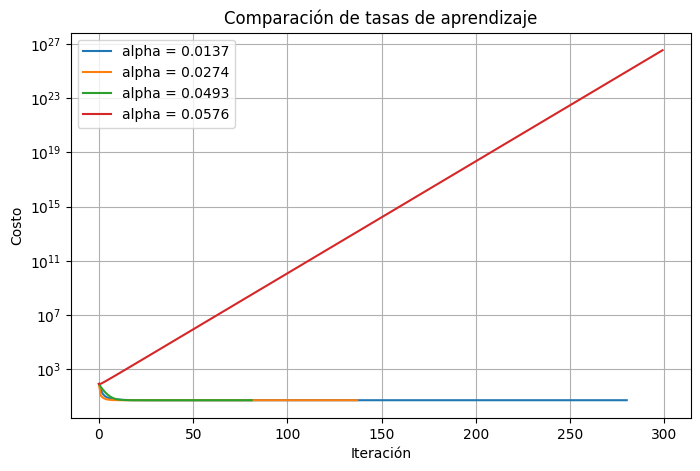

In [90]:
# definimos tasas dentro y fuera del intervalo de estabilidad
alphas_prueba = [
    0.5 / mu_max,
    1 / mu_max,
    1.8 / mu_max,
    2.1 / mu_max
]

plt.figure(figsize=(8, 5))

for alpha in alphas_prueba:
    # hacemos una reconstrucción de prueba
    x_prueba, costos, errores, iteraciones = gradiente_descendiente_regularizado(A7, b_sigmas[0.20], D, 1, alpha, x_fantoma, max_iter=300)

    # graficamos la evolución del costo
    plt.plot(costos, label=f"alpha = {alpha:.4f}")

plt.yscale("log")
plt.xlabel("Iteración")
plt.ylabel("Costo")
plt.title("Comparación de tasas de aprendizaje")
plt.legend()
plt.grid()
plt.show()

In [91]:
# elegimos una tasa de aprendizaje estable
alpha_elegido = 1 / mu_max

print("Alpha elegido:", alpha_elegido)

Alpha elegido: 0.02741473798424806


In [92]:
# acá guardamos los resultados de todas las reconstrucciones
resultados = {}

for sigma in sigmas:
    for lamb in lambdas:
        # recuperamos las mediciones correspondientes a este sigma
        b_sigma = b_sigmas[sigma]

        # hacemos la reconstrucción
        x_rec, costos, errores, iteraciones = gradiente_descendiente_regularizado(A7, b_sigma, D, lamb, alpha_elegido, x_fantoma, max_iter=5000, tolerancia=1e-6)

        # guardamos los resultados
        resultados[(sigma, lamb)] = {"x": x_rec, "costos": costos, "errores": errores, "iteraciones": iteraciones}

        print("sigma =", sigma, "- lambda =", lamb, "- iteraciones =", iteraciones)

sigma = 0 - lambda = 0 - iteraciones = 756
sigma = 0 - lambda = 0.1 - iteraciones = 490
sigma = 0 - lambda = 0.3 - iteraciones = 296
sigma = 0 - lambda = 1 - iteraciones = 135
sigma = 0.1 - lambda = 0 - iteraciones = 724
sigma = 0.1 - lambda = 0.1 - iteraciones = 483
sigma = 0.1 - lambda = 0.3 - iteraciones = 290
sigma = 0.1 - lambda = 1 - iteraciones = 122
sigma = 0.2 - lambda = 0 - iteraciones = 793
sigma = 0.2 - lambda = 0.1 - iteraciones = 526
sigma = 0.2 - lambda = 0.3 - iteraciones = 318
sigma = 0.2 - lambda = 1 - iteraciones = 138


Probamos distintas tasas de aprendizaje y observamos que las tasas dentro del intervalo de estabilidad producen un descenso del costo. En cambio, la tasa ubicada fuera del intervalo genera un comportamiento inestable.

Elegimos $\alpha=1/\mu_{\max}$ porque produjo un descenso estable. También utilizamos como criterio de parada que la norma del gradiente sea menor que $10^{-6}$ y establecimos un máximo de 5000 iteraciones.

## g) Evolución del error relativo

Para cada nivel de ruido, graficamos el error relativo en función de las iteraciones para los distintos valores de $\lambda$.

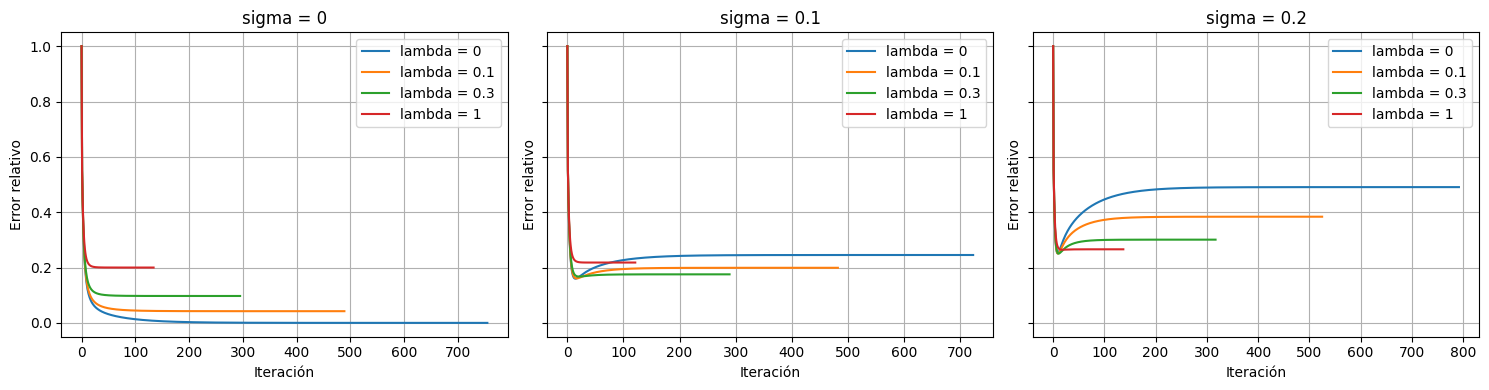

In [93]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for indice, sigma in enumerate(sigmas):
    for lamb in lambdas:
        # recuperamos los errores de esta combinación
        errores = resultados[(sigma, lamb)]["errores"]

        # graficamos el error relativo
        axes[indice].plot(errores, label=f"lambda = {lamb}")

    axes[indice].set_title(f"sigma = {sigma}")
    axes[indice].set_xlabel("Iteración")
    axes[indice].set_ylabel("Error relativo")
    axes[indice].grid()
    axes[indice].legend()

plt.tight_layout()
plt.show()

## h) Grilla de reconstrucciones

Organizamos las reconstrucciones finales en una grilla. Cada fila corresponde a un valor de $\sigma$ y cada columna a un valor de $\lambda$. Utilizamos la misma escala de color en todas las imágenes e indicamos el error relativo de cada reconstrucción.

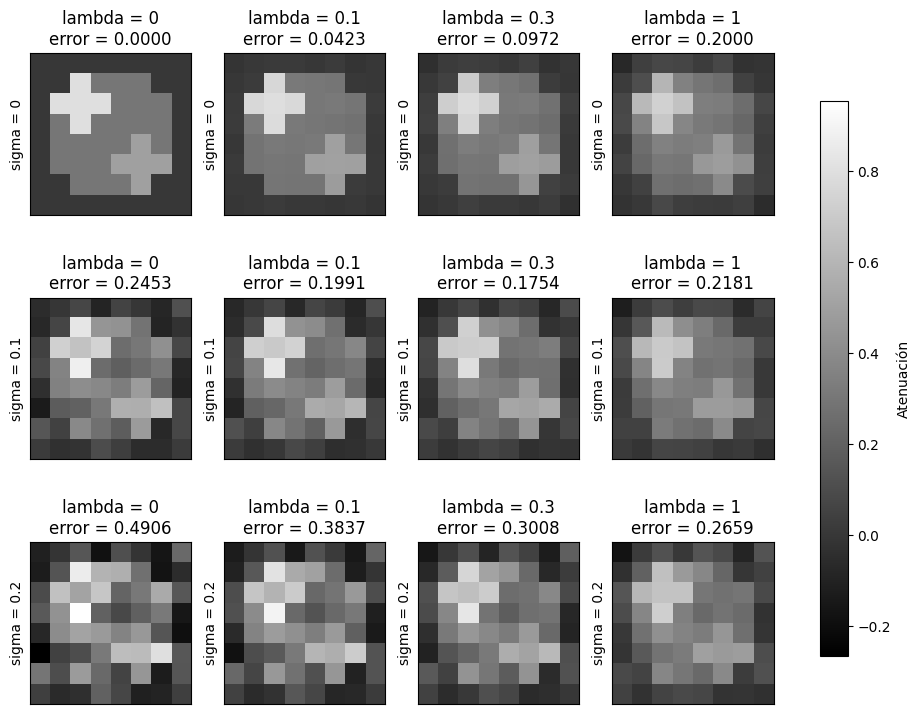

In [94]:
# buscamos los valores mínimo y máximo de todas las reconstrucciones
vmin = min(resultados[(sigma, lamb)]["x"].min() for sigma in sigmas for lamb in lambdas)
vmax = max(resultados[(sigma, lamb)]["x"].max() for sigma in sigmas for lamb in lambdas)

# creamos la grilla
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, sigma in enumerate(sigmas):
    for j, lamb in enumerate(lambdas):
        # recuperamos la reconstrucción
        x_rec = resultados[(sigma, lamb)]["x"]
        X_rec = x_rec.reshape(n, n)

        # calculamos el error relativo final
        error_final = np.linalg.norm(x_rec - x_fantoma) / np.linalg.norm(x_fantoma)

        # mostramos la reconstrucción
        im = axes[i, j].imshow(X_rec, cmap="gray", vmin=vmin, vmax=vmax)
        axes[i, j].set_title(f"lambda = {lamb}\nerror = {error_final:.4f}")
        axes[i, j].set_ylabel(f"sigma = {sigma}")
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

# agregamos una escala de color común
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8, label="Atenuación")

plt.show()

## i) Comparación de errores y residuos

Calculamos el error relativo y la norma del residuo para cada combinación de $\sigma$ y $\lambda$. Luego identificamos qué valor de $\lambda$ produjo el menor error para cada nivel de ruido.

In [96]:
# creamos las matrices donde vamos a guardar los resultados
errores_finales = np.zeros((len(sigmas), len(lambdas)))
normas_residuos = np.zeros((len(sigmas), len(lambdas)))

for i, sigma in enumerate(sigmas):
    for j, lamb in enumerate(lambdas):
        # recuperamos la reconstrucción
        x_rec = resultados[(sigma, lamb)]["x"]

        # calculamos el error relativo
        error = np.linalg.norm(x_rec - x_fantoma) / np.linalg.norm(x_fantoma)
        errores_finales[i, j] = error

        # calculamos la norma del residuo
        residuo = A7 @ x_rec - b_sigmas[sigma]
        normas_residuos[i, j] = np.linalg.norm(residuo)


def mostrar_tabla(titulo, datos):
    print()
    print(titulo)

    # construimos el encabezado
    encabezado = "sigma".ljust(12)

    for lamb in lambdas:
        encabezado += ("lambda = " + str(lamb)).rjust(15)

    print(encabezado)
    print("-" * len(encabezado))

    # mostramos una fila por cada valor de sigma
    for i, sigma in enumerate(sigmas):
        fila = str(sigma).ljust(12)

        for valor in datos[i]:
            fila += f"{valor:>15.4f}"

        print(fila)


# mostramos las dos tablas
mostrar_tabla("ERRORES RELATIVOS", errores_finales)
mostrar_tabla("NORMAS DE LOS RESIDUOS", normas_residuos)



ERRORES RELATIVOS
sigma            lambda = 0   lambda = 0.1   lambda = 0.3     lambda = 1
------------------------------------------------------------------------
0                    0.0000         0.0423         0.0972         0.2000
0.1                  0.2453         0.1991         0.1754         0.2181
0.2                  0.4906         0.3837         0.3008         0.2659

NORMAS DE LOS RESIDUOS
sigma            lambda = 0   lambda = 0.1   lambda = 0.3     lambda = 1
------------------------------------------------------------------------
0                    0.0000         0.2008         0.5040         1.1594
0.1                  0.9070         0.9388         1.0767         1.5619
0.2                  1.8141         1.8476         1.9712         2.3771


In [97]:
print()
print("MEJOR LAMBDA PARA CADA NIVEL DE RUIDO")

# armamos el encabezado
encabezado = "sigma".ljust(12)
encabezado += "Mejor lambda".rjust(18)
encabezado += "Menor error".rjust(18)

print(encabezado)
print("-" * len(encabezado))

for i, sigma in enumerate(sigmas):
    # buscamos la posición del menor error de esta fila
    indice_mejor = np.argmin(errores_finales[i])

    # recuperamos el lambda y el error correspondientes
    mejor_lambda = lambdas[indice_mejor]
    menor_error = errores_finales[i, indice_mejor]

    # armamos la fila de resultados
    fila = str(sigma).ljust(12)
    fila += str(mejor_lambda).rjust(18)
    fila += f"{menor_error:>18.4f}"

    print(fila)


MEJOR LAMBDA PARA CADA NIVEL DE RUIDO
sigma             Mejor lambda       Menor error
------------------------------------------------
0                            0            0.0000
0.1                        0.3            0.1754
0.2                          1            0.2659


Para $\sigma=0$, el menor error se obtuvo con $\lambda=0$, con un error prácticamente nulo.

Para $\sigma=0.10$, el menor error se obtuvo con $\lambda=0.3$, con un error relativo de $0.1754$.

Para $\sigma=0.20$, el menor error se obtuvo con $\lambda=1$, con un error relativo de $0.2659$.

## j) Análisis de los resultados

Para $\sigma=0$, la regularización no mejoró la reconstrucción. Con $\lambda=0$ obtuvimos un error prácticamente nulo, mientras que el error aumentó al incrementar $\lambda$.

Para $\sigma=0.10$, todos los valores de regularización mejoraron el resultado obtenido con $\lambda=0$. El menor error se obtuvo con $\lambda=0.3$.

Para $\sigma=0.20$, la regularización también mejoró la reconstrucción en todos los casos. El menor error se obtuvo con $\lambda=1$.

Por lo tanto, el valor más conveniente de $\lambda$ aumentó al aumentar el nivel de ruido. Cuando las mediciones tienen más ruido, necesitamos una regularización más fuerte.

Una regularización excesiva produce una imagen demasiado suave y puede borrar detalles. Esto se observa para $\sigma=0.10$, donde aumentar $\lambda$ de $0.3$ a $1$ hizo que el error volviera a aumentar. También observamos que la norma del residuo aumenta con $\lambda$, porque una regularización más fuerte prioriza la suavidad y se ajusta menos a las mediciones.